# INVESTIGACIÓN DE OPERACIONES AVANZADA — DOCTORADO EN INGENIERÍA DE PROCESOS
## Día 1 · Formulación y Optimización Lineal
### Caso guía: Centro de Procesamiento de Servicios (servicios técnicos de ingeniería)

El Centro atiende solicitudes de clientes industriales (estudios de desempeño de procesos, balances de masa y energía, evaluaciones de equipos y conceptos técnicos). Hay dos tipos de solicitud, **Estándar** y **Prioritaria**, y tres etapas compartidas:

| Etapa | Actividad técnica |
|---|---|
| **Análisis** | Desarrollo del estudio técnico: datos del proceso, cálculos, modelado y redacción |
| **Validación** | Revisión técnica independiente de cálculos, supuestos y consistencia del informe |
| **Cierre** | Entrega al cliente: informe final, presentación, ajustes y aprobación |

**Pregunta del día:** ¿qué combinación de solicitudes conviene atender y qué tan firme es esa decisión?

**Taller del Día 1 — un solo notebook**
- **Parte A (Temas 1 a 3):** formulación y solución del modelo lineal.
- **Parte B (Temas 4 a 6):** sensibilidad, evaluación de una oferta y decisión con costo fijo (variable binaria).
- **informe de decisión v1:** se diligencia durante la clase, en los espacios de trabajo indicados, y se entrega **al final del día** junto con el notebook ejecutado. El informe crece durante la semana (v1 a v4) y es el punto de partida de la ruta A (Centro) del proyecto final.

> **Unidades monetarias:** pesos colombianos (COP). El margen de la solicitud Estándar es $280.000 COP. El caso es sintético y no representa una organización real.

## Mapa del notebook: qué es obligatorio y qué es opcional

| Parte | Bloques | Carácter |
|---|---|---|
| A · Formulación (Temas 1 a 3) | 0 a 4 | **Obligatorio** |
| A · Retos del Taller A | 4B · Reto A1 | **Obligatorio** |
| A · Retos del Taller A | 4B · Retos A2 y A3 | Opcional |
| B · Sensibilidad y enteras (Temas 4 a 6) | 5 a 8 | **Obligatorio** |
| B · Extensiones | 9 a 13 | Opcional |
| Informe de decisión | Secciones 1 a 9 y 4b (Reto A1) | **Obligatorio** |
| Informe de decisión | Secciones 4c y 10 a 13 | Opcional |

**Lo obligatorio se puede terminar en el tiempo de clase.** Lo opcional es para quien avance más rápido o quiera profundizar; recibe retroalimentación, pero la nota se calcula solo con la rúbrica del informe obligatorio (al final del notebook).

Trabajen celda por celda con Shift+Enter, en orden. Si un bloque opcional queda sin completar, su celda de verificación muestra un aviso y no un error.

## Bloque 0 — Configuración del entorno (resuelto)

In [81]:
# Instala dos librerías en Colab (el signo ! ejecuta un comando del sistema):
#   pyomo = lenguaje en el que se escribe el modelo; highspy = HiGHS, el solver que lo resuelve.
!pip install -q pyomo highspy
# Importa Pyomo con el alias corto 'pyo': todo lo de Pyomo se escribe como pyo.Algo.
import pyomo.environ as pyo
print("Entorno listo.")

Entorno listo.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# PARTE A (Temas 1 a 3) — Formulación y solución del modelo lineal

## Bloque 1 — Parámetros técnicos y económicos (resuelto)

In [82]:
# 1) Crea el modelo vacío. 'm' es el contenedor donde irán conjuntos, parámetros, variables, objetivo y restricciones.
#    ConcreteModel: cada componente se construye con sus datos en el momento en que se declara.
m = pyo.ConcreteModel(name="Centro_Procesamiento")

# 2) Conjuntos: las listas de nombres sobre las que se indexa todo.
#    pyo.Set es el conjunto de Pyomo; funciona como una lista de nombres que se puede recorrer.
m.SOLICITUDES = pyo.Set(initialize=['Estandar', 'Prioritaria'])  # tipos de solicitud (índice s)
m.ETAPAS      = pyo.Set(initialize=['Analisis', 'Validacion', 'Cierre'])  # etapas del proceso (índice e)

# 3) Datos del caso en diccionarios de Python (clave: valor). Todavía no forman parte del modelo.
margen_cop_solicitud = {'Estandar': 280000.0, 'Prioritaria': 210000.0}  # margen por solicitud atendida, COP
capacidad_horas_equipo = {'Analisis': 40.0, 'Validacion': 48.0, 'Cierre': 36.0}  # h-eq disponibles por día en cada etapa

# Diccionario con clave doble (etapa, tipo): h-eq que consume UNA solicitud de ese tipo en esa etapa.
# Ejemplo: ('Validacion', 'Estandar'): 2.4 → una Estándar consume 2,4 h-eq en Validación.
tasa_procesamiento = {
    ('Analisis', 'Estandar'): 1.6, ('Analisis', 'Prioritaria'): 1.0,
    ('Validacion', 'Estandar'): 2.4, ('Validacion', 'Prioritaria'): 1.2,
    ('Cierre', 'Estandar'): 0.8, ('Cierre', 'Prioritaria'): 1.8
}

# 4) Parámetros de Pyomo (pyo.Param): llevan los diccionarios al modelo, indexados por los conjuntos.
#    m.c[s] = margen (coeficiente del objetivo); m.b[e] = capacidad (lado derecho de la restricción);
#    m.a[e, s] = horas por solicitud (coeficientes de las restricciones).
m.c = pyo.Param(m.SOLICITUDES, initialize=margen_cop_solicitud)  # margen por tipo de solicitud
m.b = pyo.Param(m.ETAPAS, initialize=capacidad_horas_equipo)  # capacidad por etapa
m.a = pyo.Param(m.ETAPAS, m.SOLICITUDES, initialize=tasa_procesamiento)  # horas por solicitud, por etapa y tipo

# Confirma que el bloque se ejecutó sin errores.
print("Parámetros cargados.")

# Salida del bloque: muestra lo que se cargó, para compararlo con la tabla de parámetros de la presentación.
print("\nMargen por solicitud (COP por solicitud):")
for s in m.SOLICITUDES:
    print(f"  {s:<12} {m.c[s]:>10,.0f}".replace(",", "."))   # el punto es el separador de miles

print("\nCapacidad por etapa (h-eq por día):")
for e in m.ETAPAS:
    print(f"  {e:<12} {m.b[e]:>6.1f}")

print("\nConsumo por solicitud (h-eq que consume una solicitud en cada etapa):")
print(f"  {'Etapa':<12}" + "".join(f"{s:>13}" for s in m.SOLICITUDES))
for e in m.ETAPAS:
    print(f"  {e:<12}" + "".join(f"{m.a[e, s]:>13.1f}" for s in m.SOLICITUDES))


Parámetros cargados.

Margen por solicitud (COP por solicitud):
  Estandar        280.000
  Prioritaria     210.000

Capacidad por etapa (h-eq por día):
  Analisis       40.0
  Validacion     48.0
  Cierre         36.0

Consumo por solicitud (h-eq que consume una solicitud en cada etapa):
  Etapa            Estandar  Prioritaria
  Analisis              1.6          1.0
  Validacion            2.4          1.2
  Cierre                0.8          1.8


## Bloque 2 — Trabajo guiado del doctorando [TODO]

Complete las tres actividades. Use el Bloque 3 para verificar su trabajo antes de pasar al Bloque 4.

In [83]:
# ACTIVIDAD 1: Declare la variable continua x indexada en SOLICITUDES (no negativa)
m.x = pyo.Var(m.SOLICITUDES, domain=pyo.NonNegativeReals)


# ACTIVIDAD 2: Declare la Función Objetivo de maximización del margen diario
def regla_obj(mod):
    return sum(mod.c[s] * mod.x[s] for s in mod.SOLICITUDES)

m.obj = pyo.Objective(rule=regla_obj, sense=pyo.maximize)


# ACTIVIDAD 3: Declare las restricciones de capacidad por etapa
def regla_cap(mod, e):
    return sum(mod.a[e, s] * mod.x[s] for s in mod.SOLICITUDES) <= mod.b[e]

m.rest_capacidad = pyo.Constraint(m.ETAPAS, rule=regla_cap)

## Bloque 3 — Comprobación estructural (resuelto)

In [84]:
# Comprobación estructural: assert detiene la ejecución con un mensaje si algo no se cumple.
# Verifica que el modelo tenga todo lo declarado antes de resolverlo.
assert m.x is not None, "Error de verificación: la variable m.x no ha sido declarada."
assert m.obj is not None, "Error de verificación: la función objetivo no ha sido asignada."
assert m.rest_capacidad is not None, "Error de verificación: restricciones de capacidad no encontradas."
assert len(m.x) == 2, f"Error estructural: se esperaban 2 variables, hay {len(m.x)}."  # 2 variables: una por tipo de solicitud
assert len(m.rest_capacidad) == 3, "Error estructural: se esperaban 3 restricciones de etapa."  # 3 restricciones: una por etapa
print("✓ Verificación estructural del modelo aprobada.")

✓ Verificación estructural del modelo aprobada.


## Bloque 4 — Solución e interpretación (resuelto)

El solver entrega el plan óptimo, la holgura de cada etapa y su precio sombra (variación del margen por cada hora-equipo adicional de capacidad).

In [85]:
# Función auxiliar: da formato de pesos colombianos (punto como separador de miles) a un número.
def cop(v):
    """Formato de pesos con punto como separador de miles."""
    return f"{v:,.0f}".replace(",", ".")

# Pide al solver los precios sombra (variables duales). Suffix IMPORT = traer información del solver al modelo.
m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
# Crea el solver HiGHS (appsi_highs). Es el programa que busca el plan óptimo.
solver = pyo.SolverFactory('appsi_highs')
# try/except atrapa el error del solver y lo cambia por un mensaje en español que orienta.
try:
    results = solver.solve(m)  # aquí se resuelve el modelo; results guarda el estado de la solución
except RuntimeError:
    raise AssertionError("El solver no pudo resolver el modelo. Revise el sentido de las restricciones de capacidad (deben ser <=) y que x sea no negativa.")

# Verifica que el solver terminó con una solución óptima.
assert pyo.check_optimal_termination(results), "El solver no encontró un óptimo finito. Pista: revise el sentido de las desigualdades de capacidad (<=)."

# Comprobación física: en cada etapa, las horas usadas (Σ a·x) no pueden superar la capacidad (1e-6 = tolerancia numérica).
for e in m.ETAPAS:
    consumo = sum(pyo.value(m.a[e, s]) * pyo.value(m.x[s]) for s in m.SOLICITUDES)  # horas usadas en la etapa e
    assert consumo <= pyo.value(m.b[e]) + 1e-6, f"Infactibilidad física detectada en {e}."

print("✓ Comprobación sustantiva exitosa: solución óptima y físicamente admisible.")
# Informe de resultados: margen óptimo Z*, plan óptimo y, por etapa, holgura y precio sombra.
print("\n" + "=" * 62)
print("                 RESULTADOS DEL MODELO")
print("=" * 62)
print(f"Estado del solver:           {results.solver.termination_condition}")
print(f"Margen óptimo Z*:            ${cop(pyo.value(m.obj))} COP/día")  # pyo.value(...) extrae el número del objeto de Pyomo
# Plan óptimo: cuántas solicitudes de cada tipo por día.
for s in m.SOLICITUDES:
    print(f"Solicitudes {s + ':':<14}  {pyo.value(m.x[s]):.2f} por día")
print("-" * 62)
# Por etapa: holgura = capacidad − uso; precio sombra = valor de una hora-equipo adicional (dual de la restricción).
for e in m.ETAPAS:
    consumo = sum(m.a[e, s] * pyo.value(m.x[s]) for s in m.SOLICITUDES)
    holgura = pyo.value(m.b[e]) - consumo  # capacidad − uso
    sombra  = m.dual[m.rest_capacidad[e]]  # dual de la restricción de la etapa e
    estado  = "activa" if holgura < 1e-6 else "con holgura"  # 'activa' = etapa llena (cuello de botella)
    print(f"{e:11} | holgura: {holgura:6.2f} h-eq | precio sombra: ${cop(sombra):>8} COP/h | {estado}")
print("=" * 62)

✓ Comprobación sustantiva exitosa: solución óptima y físicamente admisible.

                 RESULTADOS DEL MODELO
Estado del solver:           optimal
Margen óptimo Z*:            $6.600.000 COP/día
Solicitudes Estandar:       12.86 por día
Solicitudes Prioritaria:    14.29 por día
--------------------------------------------------------------
Analisis    | holgura:   5.14 h-eq | precio sombra: $       0 COP/h | con holgura
Validacion  | holgura:   0.00 h-eq | precio sombra: $ 100.000 COP/h | activa
Cierre      | holgura:   0.00 h-eq | precio sombra: $  50.000 COP/h | activa


## Bloque 4C (opcional) — Visualización gráfica de la región factible

Como el modelo tiene solo dos variables (Estándar y Prioritaria), la región factible y el plan óptimo se pueden graficar en el plano x₁-x₂.

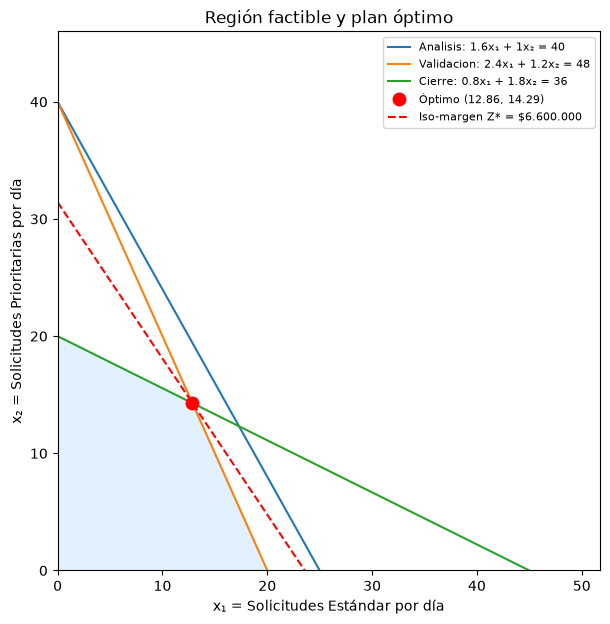

In [86]:
import numpy as np
import matplotlib.pyplot as plt

# Rango de valores para graficar en el plano (x1 = Estándar, x2 = Prioritaria).
x1_max = max(m.b[e] / m.a[e, 'Estandar'] for e in m.ETAPAS) * 1.15
x2_max = max(m.b[e] / m.a[e, 'Prioritaria'] for e in m.ETAPAS) * 1.15
x1 = np.linspace(0, x1_max, 400)

fig, ax = plt.subplots(figsize=(7, 7))

# Línea de cada restricción de capacidad: a[e,Estandar]*x1 + a[e,Prioritaria]*x2 = b[e]
colores = {'Analisis': 'tab:blue', 'Validacion': 'tab:orange', 'Cierre': 'tab:green'}
for e in m.ETAPAS:
    a1, a2, b = m.a[e, 'Estandar'], m.a[e, 'Prioritaria'], m.b[e]
    x2_linea = (b - a1 * x1) / a2
    ax.plot(x1, x2_linea, label=f"{e}: {a1:g}x₁ + {a2:g}x₂ = {b:g}", color=colores[e])

# Región factible: malla fina sombreada donde se cumplen las tres restricciones y x1, x2 >= 0.
X1, X2 = np.meshgrid(np.linspace(0, x1_max, 300), np.linspace(0, x2_max, 300))
factible = np.ones_like(X1, dtype=bool)
for e in m.ETAPAS:
    factible &= (m.a[e, 'Estandar'] * X1 + m.a[e, 'Prioritaria'] * X2 <= m.b[e] + 1e-9)
ax.contourf(X1, X2, factible.astype(int), levels=[0.5, 1.5], colors=['#cfe8ff'], alpha=0.6)

# Punto óptimo entregado por el solver.
x1_opt, x2_opt = pyo.value(m.x['Estandar']), pyo.value(m.x['Prioritaria'])
ax.plot(x1_opt, x2_opt, 'ro', markersize=9, zorder=5,
        label=f"Óptimo ({x1_opt:.2f}, {x2_opt:.2f})")

# Línea de iso-margen que pasa por el óptimo: c1*x1 + c2*x2 = Z*.
Z = pyo.value(m.obj)
c1, c2 = m.c['Estandar'], m.c['Prioritaria']
x2_isolinea = (Z - c1 * x1) / c2
ax.plot(x1, x2_isolinea, 'r--', linewidth=1.5,
        label=f"Iso-margen Z* = ${Z:,.0f}".replace(",", "."))

ax.set_xlim(0, x1_max)
ax.set_ylim(0, x2_max)
ax.set_xlabel("x₁ = Solicitudes Estándar por día")
ax.set_ylabel("x₂ = Solicitudes Prioritarias por día")
ax.set_title("Región factible y plan óptimo")
ax.legend(loc="upper right", fontsize=8)
plt.show()

## Bloque 4B — Retos de modificación del modelo [TODO] (Taller A, parte final)

**Reto A1: obligatorio. Retos A2 y A3: opcionales.**

Con el modelo resuelto y verificado, ahora lo van a **modificar y poner a prueba**. Son tres retos independientes; trabájenlos en orden. Cada reto tiene su celda de verificación.

- **Reto A1 (obligatorio):** el convenio exige atender **al menos 18 solicitudes Prioritarias por día**. ¿Cuánto margen cuesta ese compromiso?
- **Reto A2 (opcional):** construyan una función que resuelva el caso con otros márgenes y capacidades, y úsenla para probar tres márgenes de Prioritarias.
- **Reto A3 (opcional):** ¿basta con redondear el plan óptimo? Evalúen los cuatro redondeos posibles.

In [87]:
# RETO A1 (OBLIGATORIO) — Compromiso del convenio: x['Prioritaria'] >= 18
# Pista: clone del modelo (m.clone()), agregue UNA restricción nueva y resuelva.
m_a1 = m.clone()

# Restricción de mínimo 18 Prioritarias por día.
m_a1.minimo_prio = pyo.Constraint(expr=m_a1.x['Prioritaria'] >= 18)

# Resuelve m_a1 con appsi_highs y guarda los resultados.
pyo.SolverFactory('appsi_highs').solve(m_a1)

Z_a1 = pyo.value(m_a1.obj)            # margen óptimo con el compromiso
x_a1 = {s: pyo.value(m_a1.x[s]) for s in m_a1.SOLICITUDES}   # diccionario {'Estandar': ..., 'Prioritaria': ...}

In [88]:
# Verifica que el reto se resolvió y muestra el costo del compromiso frente al plan sin compromiso.
assert Z_a1 is not None and x_a1 is not None, "Falta resolver m_a1 y guardar Z_a1 y x_a1."
assert x_a1['Prioritaria'] >= 18 - 1e-6, "El plan no cumple el mínimo de 18 Prioritarias."
print(f"Margen con el compromiso:   ${cop(Z_a1)} COP/día")
print(f"Costo del compromiso:       ${cop(pyo.value(m.obj) - Z_a1)} COP/día frente al plan óptimo")
print(f"Plan: Estándar {x_a1['Estandar']:.2f}, Prioritaria {x_a1['Prioritaria']:.2f}")
# Interprete: ¿qué etapas limitan ahora el plan, y qué cambió frente al plan sin compromiso? Anótelo en el informe (sección 4b).

Margen con el compromiso:   $5.040.000 COP/día
Costo del compromiso:       $1.560.000 COP/día frente al plan óptimo
Plan: Estándar 4.50, Prioritaria 18.00


In [89]:
# RETO A2 (OPCIONAL) — Función que resuelve el caso con otros datos
def resolver_caso(margen, capacidad):
    """Construye y resuelve el LP con los márgenes y capacidades recibidos.
    margen: dict por solicitud; capacidad: dict por etapa. Devuelve (Z, {x})."""
    # Modelo nuevo, independiente de m.
    mm = pyo.ConcreteModel()
    # Conjuntos copiados de m (list(...) los vuelve listas de Python).
    mm.S = pyo.Set(initialize=list(m.SOLICITUDES))
    mm.E = pyo.Set(initialize=list(m.ETAPAS))
    # Variables no negativas, objetivo (maximizar) y restricciones de capacidad.
    mm.x = pyo.Var(mm.S, domain=pyo.NonNegativeReals)
    mm.obj = pyo.Objective(expr=sum(margen[s] * mm.x[s] for s in mm.S), sense=pyo.maximize)
    mm.r = pyo.Constraint(mm.E, rule=lambda md, e: sum(tasa_procesamiento[e, s] * md.x[s] for s in md.S) <= capacidad[e])
    # Resuelve mm con HiGHS.
    pyo.SolverFactory('appsi_highs').solve(mm)
    return pyo.value(mm.obj), {s: pyo.value(mm.x[s]) for s in mm.S}  # devuelve el margen Z y el plan {tipo: cantidad}


# Pruebe la función con tres márgenes de Prioritarias (Estándar se mantiene en 280.000)
# Barrido: se resuelve el caso con tres márgenes distintos de Prioritarias.
resultados_a2 = {}
for mp in (120000.0, 300000.0, 700000.0):
    margen_prueba = dict(margen_cop_solicitud)
    margen_prueba['Prioritaria'] = mp
    resultados_a2[mp] = resolver_caso(margen_prueba, capacidad_horas_equipo)

In [90]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert len(resultados_a2) == 3, "Falta evaluar los tres márgenes de Prioritarias."
    # Tabla: margen de Prioritarias, Z óptimo y plan para cada escenario.
    print(f"{'Margen Prioritaria':>20} | {'Z (COP/día)':>14} | {'Estándar':>9} | {'Prioritaria':>11}")
    for mp, (Z, x) in resultados_a2.items():
        print(f"{cop(mp):>20} | {cop(Z):>14} | {x['Estandar']:9.2f} | {x['Prioritaria']:11.2f}")
    # Interprete: ¿en cuál de los tres escenarios cambia el plan? ¿Por qué el plan no cambia siempre?
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

  Margen Prioritaria |    Z (COP/día) |  Estándar | Prioritaria
             120.000 |      5.600.000 |     20.00 |        0.00
             300.000 |      7.885.714 |     12.86 |       14.29
             700.000 |     14.000.000 |      0.00 |       20.00


In [91]:
# RETO A3 (OPCIONAL) — ¿Basta con redondear el plan óptimo?
# product(a, b) genera todas las combinaciones de dos listas: aquí, los 4 redondeos posibles del plan.
from itertools import product

def es_factible(x1, x2):
    """True si el plan (x1, x2) cumple las tres capacidades."""
    # TODO: revise cada etapa con tasa_procesamiento y capacidad_horas_equipo
    return None

def margen_plan(x1, x2):
    # TODO: margen del plan con margen_cop_solicitud
    return None

# Evalúa los 4 redondeos del plan óptimo (12,86 y 14,29): 12 o 13 Estándar, 14 o 15 Prioritarias.
tabla_a3 = []
for x1, x2 in product((12, 13), (14, 15)):
    tabla_a3.append((x1, x2, es_factible(x1, x2), margen_plan(x1, x2)))

In [92]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert all(f is not None and z is not None for _, _, f, z in tabla_a3), "Complete es_factible y margen_plan."
    # Tabla de los cuatro redondeos: si son factibles y cuánto margen dan.
    print(f"{'x1':>3} {'x2':>3} | {'Factible':>8} | {'Margen (COP/día)':>17}")
    for x1, x2, f, z in tabla_a3:
        print(f"{x1:>3} {x2:>3} | {str(f):>8} | {cop(z):>17}")
    # Interprete: ¿qué redondeo es el mejor plan entero factible? ¿Por qué no se puede redondear "hacia arriba" siempre?
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

Bloque opcional sin completar o por revisar: Complete es_factible y margen_plan.
Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.


---

# INFORME DE DECISIÓN — v1 · Parte A

*Complete las secciones 1 a 4 después de ejecutar el Bloque 4 (se completa en el Tema 4).*

## 1. Problema
_[Describa en 2-3 líneas la decisión que enfrenta el Centro.]_

El Centro debe decidir cuántas solicitudes Estándar y cuántas Prioritarias atender cada día, sabiendo que ambos tipos comparten tres etapas (Análisis, Validación, Cierre) con capacidad limitada en horas-equipo. La decisión busca el plan que maximiza el margen diario sin exceder la capacidad de ninguna etapa.

## 2. Variables de decisión
_[x₁ = ... , x₂ = ...  (indique cuál corresponde a `m.x['Estandar']` y cuál a `m.x['Prioritaria']`)]_

x₁ = m.x['Estandar']: número de solicitudes Estándar atendidas por día.
x₂ = m.x['Prioritaria']: número de solicitudes Prioritarias atendidas por día.
Ambas son continuas y no negativas (no se exige que sean enteras en este modelo).

## 3. Plan óptimo
_[Valores de x₁*, x₂* y Z* del Bloque 4.]_

x₁* = 12,86 solicitudes Estándar/día, x₂* = 14,29 solicitudes Prioritarias/día, Z* = $6.600.000 COP/día.

## 4. Cuellos de botella
_[¿Qué etapas quedaron con holgura cero? ¿Cuál tiene el precio sombra más alto?]_

Validación y Cierre quedan con holgura cero: se usa toda su capacidad disponible, son los cuellos de botella del sistema. Análisis queda con holgura (sobran horas-equipo sin usar), por lo que no limita el plan. El precio sombra más alto es el de Validación ($100.000 COP por hora-equipo adicional), más del doble que el de Cierre ($50.000 COP/h-eq); eso dice que si se pudiera liberar capacidad en una sola etapa, convendría hacerlo en Validación, no en Cierre.

## 4b. Reto A1 — costo del compromiso de 18 Prioritarias (obligatorio)
_[Escriba: margen con el compromiso, costo frente al plan óptimo y qué etapas limitan ahora el plan, comparado con el plan sin compromiso.]_

Con el mínimo de 18 Prioritarias/día, el margen óptimo baja a $5.040.000 COP/día (plan: 4,5 Estándar, 18 Prioritarias). El compromiso cuesta $1.560.000 COP/día frente al plan óptimo sin esa restricción ($6.600.000 − $5.040.000). Además, cambia qué etapa limita el plan: ya no es Validación (que ahora queda con bastante holgura) sino Cierre, junto con el propio mínimo exigido de 18 Prioritarias. Es decir, el convenio obliga a sacrificar Estándar para cumplir con Prioritarias, y esa pérdida se explica por la capacidad de Cierre, que es la etapa donde las Prioritarias consumen más horas relativas (1,8 h-eq frente a 0,8 de Análisis... revisa la tabla de tasa_procesamiento para dar la cifra exacta en tu redacción).

## 4c. Retos A2 y A3 (opcional)
_[Reto A2: en cuál de los tres márgenes cambia el plan y por qué. Reto A3: mejor redondeo factible y por qué no basta con redondear.]_

Con cada uno de los tres márgenes que pide probar (120.000 / 300.000 / 700.000), manteniendo Estándar fijo en 280.000:

Referencia clave: en el Bloque 11 (si lo completas) vas a encontrar que el plan óptimo (12,86 Estándar / 14,29 Prioritaria) se mantiene mientras el margen de Prioritaria esté entre ~140.000 y ~630.000. Fuera de ese rango, cambia a qué tipo de solicitud le conviene dedicar toda la capacidad.

Con margen = 120.000 (por debajo del rango):
El plan cambia a x₁=20, x₂=0 — deja de atender Prioritarias por completo. Al bajar tanto su margen, ya no compensa usar capacidad en ellas; el margen total es $5.600.000 COP/día (el máximo ahora se logra llenando Validación solo con Estándar).

Con margen = 300.000 (dentro del rango):
El plan no cambia: sigue siendo x₁=12,86, x₂=14,29. Está dentro del intervalo de validez, así que la combinación óptima se mantiene (el margen total sube a ~$7.885.714 COP/día, pero la composición del plan es la misma).

Con margen = 700.000 (por encima del rango):
El plan cambia a x₁=0, x₂=20 — ahora conviene dedicar toda la capacidad a Prioritarias. Con un margen tan alto, maximizar Prioritarias (limitado solo por Cierre) da más margen total ($14.000.000 COP/día) que mantener la mezcla.

La idea para explicar el "por qué": el plan óptimo de un LP solo cambia cuando el margen relativo entre los dos tipos cruza el punto donde otro vértice de la región factible pasa a ser mejor. Dentro del rango de validez, la mezcla original sigue siendo la mejor combinación; fuera de él, conviene "irse a una esquina" (todo Estándar o todo Prioritaria) porque ya no hay equilibrio entre ambos.

## 5. Cuellos de botella
_[¿Cuanto cambia el margen si se agrega una hora-equipo en cada etapa?]_

En el plan óptimo ya le sobran ~5,14 horas-equipo (no se usa toda su capacidad), así que agregar una más no cambia la solución ni el margen — el precio sombra de una restricción con holgura siempre es 0.

Validación es el cuello de botella "más caro" — cada hora adicional ahí vale el doble que en Cierre, porque es la restricción que más limita la combinación óptima de Estándar y Prioritaria.

## 6. Donde invertiría primero y por qué
_[¿Dónde invertiría y por qué?]_


Conviene invertir en Validación, porque tiene el precio sombra más alto ($100.000 COP por hora-equipo adicional), el doble que Cierre ($50.000) y muy por encima de Análisis ($0 — ahí sobra capacidad, invertir ahí no sirve de nada porque no es un cuello de botella).
El precio sombra dice cuánto margen adicional genera cada hora extra en esa etapa. Si tienes un presupuesto limitado para ampliar capacidad, la regla es simple: inviertes primero donde el retorno marginal es mayor. Como Validación "vale" el doble que Cierre por hora, cada peso invertido ahí rinde más.


# PARTE B (Temas 4 a 6) — Sensibilidad y decisiones enteras

## Bloque 5 — Rangos de validez de los precios sombra (resuelto)

El precio sombra es válido mientras la base óptima no cambie. Esta función resuelve el modelo de nuevo con una capacidad modificada y busca, por bisección, el intervalo de capacidad en el que el precio sombra se mantiene.

In [113]:
# Función central del notebook: construye y resuelve de nuevo el modelo con capacidades (b) o márgenes (c) modificados, sin tocar m.
def resolver(b=None, c=None, fijar_cero=()):
    """Resuelve el LP del caso con capacidades (b) o márgenes (c) modificados.
    Devuelve (Z, {x}, {precio sombra por etapa})."""
    # Modelo nuevo; se reconstruye desde cero en cada llamada.
    mm = pyo.ConcreteModel()
    # Conjuntos copiados de m (S: tipos de solicitud; E: etapas).
    mm.S = pyo.Set(initialize=list(m.SOLICITUDES))
    mm.E = pyo.Set(initialize=list(m.ETAPAS))
    # Copia los datos base y reemplaza solo los que llegan modificados (update).
    cc = dict(margen_cop_solicitud); cc.update(c or {})
    bb = dict(capacidad_horas_equipo); bb.update(b or {})  # igual para las capacidades
    # Variable de decisión: cantidad de cada tipo de solicitud, no negativa.
    mm.x = pyo.Var(mm.S, domain=pyo.NonNegativeReals)
    # Si se pide, fija en 0 las variables indicadas (por ejemplo, no atender Prioritarias).
    for s in fijar_cero:
        mm.x[s].fix(0)
    # Objetivo: maximizar el margen total, Σ cc[s]·x[s].
    mm.obj = pyo.Objective(expr=sum(cc[s] * mm.x[s] for s in mm.S), sense=pyo.maximize)
    # Restricción de capacidad, una por etapa: Σ tasa·x ≤ bb[e]. lambda es una función corta (md = el modelo, e = la etapa).
    mm.r = pyo.Constraint(mm.E, rule=lambda md, e: sum(tasa_procesamiento[e, s] * md.x[s] for s in md.S) <= bb[e])
    # Pide los precios sombra al solver.
    mm.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    # Resuelve con HiGHS.
    pyo.SolverFactory('appsi_highs').solve(mm)
    # Devuelve tres cosas: margen óptimo Z, plan {tipo: cantidad} y precios sombra {etapa: valor}.
    return (pyo.value(mm.obj),
            {s: pyo.value(mm.x[s]) for s in mm.S},
            {e: mm.dual[mm.r[e]] for e in mm.E})


# Busca hasta dónde se puede mover la capacidad de una etapa sin que su precio sombra cambie (rango de validez).
# Usa BISECCIÓN: prueba el punto medio y descarta la mitad donde no está el límite.
def rango_capacidad(etapa, tope=1000.0, tol=1e-4):
    """Intervalo de capacidad de `etapa` en el que su precio sombra no cambia."""
    base = capacidad_horas_equipo[etapa]  # capacidad actual de la etapa
    p0 = resolver()[2][etapa]  # precio sombra actual
    mismo = lambda v: abs(resolver(b={etapa: v})[2][etapa] - p0) < 1.0  # True si con capacidad v el precio sombra sigue igual (tolerancia de $1)
    # límite inferior
    lo, hi = 0.0, base  # el límite inferior se busca entre 0 y la capacidad actual
    if mismo(lo):  # si el precio no cambia ni con capacidad 0, el rango llega a 0
        inferior = 0.0
    else:
        while hi - lo > tol:  # repite hasta que el intervalo sea menor que la tolerancia
            mid = (lo + hi) / 2  # punto medio del intervalo
            lo, hi = (lo, mid) if mismo(mid) else (mid, hi)  # si el precio se mantiene en mid, el límite está más abajo; si no, más arriba
        inferior = hi
    # límite superior
    lo, hi = base, tope  # el límite superior se busca entre la capacidad actual y un tope
    if mismo(hi):  # si ni en el tope cambia, no hay límite superior
        superior = float("inf")
    else:
        while hi - lo > tol:
            mid = (lo + hi) / 2
            lo, hi = (mid, hi) if mismo(mid) else (lo, mid)  # aquí al revés: si se mantiene en mid, el límite está más arriba
        superior = lo
    return inferior, superior


# Recorre las tres etapas e imprime su rango de validez.
print("Rangos de validez de la capacidad (precio sombra constante)")
print("-" * 62)
for e in m.ETAPAS:
    inf, sup = rango_capacidad(e)
    sup_txt = "sin límite superior" if sup == float("inf") else f"{sup:.2f}"
    print(f"{e:11} | base {capacidad_horas_equipo[e]:5.1f} h-eq | rango: {inf:6.2f} a {sup_txt}")

Rangos de validez de la capacidad (precio sombra constante)
--------------------------------------------------------------
Analisis    | base  40.0 h-eq | rango:  34.86 a sin límite superior
Validacion  | base  48.0 h-eq | rango:  24.00 a 56.31
Cierre      | base  36.0 h-eq | rango:  16.00 a 72.00


## Bloque 6 — Evaluación de la oferta del contratista [TODO]

Un contratista ofrece **100 horas-equipo adicionales de Validación por día**. Con el precio sombra de Validación, una extrapolación directa sugiere un aumento de margen de 100 × $100.000 = $10.000.000 COP/día. La extrapolación solo es válida dentro del rango de validez del Bloque 5. La oferta tiene un costo de **$75.000 COP por hora-equipo adicional**, es decir, $7.500.000 COP/día por las 100 horas; en la sección 6 del informe compare ese costo con el aumento real del margen.

In [114]:
# ==============================================================================
# ACTIVIDAD 4: EVALUAR LA OFERTA DEL CONTRATISTA
# ==============================================================================
# Recuperamos el margen óptimo del escenario original.
# pyo.value(m.obj) permite obtener el valor numérico de la función objetivo
# después de haber resuelto el modelo.
Z_base = pyo.value(m.obj)
# 2. Resolver nuevamente el modelo con 100 horas-equipo adicionales
# en la etapa de Validación.
## La capacidad original se encuentra en capacidad_horas_equipo.
# Use resolver() para actualizar la capacidad de Validación.
## Pista: resolver(b={'Validacion': ...})
## La función devuelve:
# Z_oferta: margen óptimo con la nueva capacidad.
# x_oferta: cantidades óptimas de solicitudes de cada tipo.
# sombra_oferta: precios sombra del nuevo escenario.
Z_oferta, x_oferta, sombra_oferta = resolver(b={'Validacion': capacidad_horas_equipo['Validacion'] + 100})
# 3. Calcular el aumento real del margen.
# Compare el margen obtenido con la oferta frente al margen original.
aumento_real = Z_oferta - Z_base
# 4. Calcular el aumento extrapolado del margen.
# Multiplique las 100 horas adicionales por el precio sombra
# de la restricción de capacidad de Validación.
# Recuerde: el precio sombra solo es válido dentro del intervalo
# de sensibilidad de la capacidad.
aumento_extrapolado = 100 * m.dual[m.rest_capacidad['Validacion']]

In [115]:
# Verifica que se calcularon los resultados y compara el aumento real con el extrapolado.
assert Z_oferta is not None, "Falta calcular Z_oferta con resolver(...)."
assert aumento_real is not None and aumento_extrapolado is not None, "Falta calcular aumento_real y aumento_extrapolado."
print(f"Margen con la oferta:        ${cop(Z_oferta)} COP/día")
print(f"Aumento real:                ${cop(aumento_real)} COP/día")
print(f"Aumento por extrapolación:   ${cop(aumento_extrapolado)} COP/día")
print(f"Relación extrapolado/real:   {aumento_extrapolado / aumento_real:.1f} veces")
print(f"Nuevo plan: Estándar {x_oferta['Estandar']:.2f}, Prioritaria {x_oferta['Prioritaria']:.2f}")
print("Precios sombra con la oferta:", {e: round(v) for e, v in sombra_oferta.items()})

Margen con la oferta:        $7.430.769 COP/día
Aumento real:                $830.769 COP/día
Aumento por extrapolación:   $10.000.000 COP/día
Relación extrapolado/real:   12.0 veces
Nuevo plan: Estándar 17.31, Prioritaria 12.31
Precios sombra con la oferta: {'Analisis': 161538, 'Validacion': 0, 'Cierre': 26923}


## Bloque 7 — Decisión con costo fijo de activación (variable binaria)

Atender solicitudes Prioritarias exige activar un equipo de convenio, con un **costo fijo de $450.000 COP/día**. Se introduce una variable binaria **y** (1 si se activa el convenio, 0 si no) y se exige que los planes sean enteros.

- Vínculo: x₂ ≤ M · y, con M = 20 (el máximo de Prioritarias que permite Cierre: 1,8 · x₂ ≤ 36).
- Objetivo: maximizar 280.000 x₁ + 210.000 x₂ − 450.000 y.

In [ ]:
# Datos y restricciones de capacidad (resueltos)
# Parámetros del escenario: costo fijo de activar el convenio con Prioritarias (COP/día) y M grande,
# una cota superior para x['Prioritaria']: el máximo que cabe en el día es 20 (Cierre: 36 / 1,8).
COSTO_FIJO = 450000.0
M_GRANDE = 20.0

# Modelo nuevo, separado de m (por eso aquí se usa m_mip.x y m_mip.y).
m_mip = pyo.ConcreteModel(name="Centro_con_costo_fijo")
m_mip.x = pyo.Var(m.SOLICITUDES, domain=pyo.NonNegativeIntegers)   # planes enteros

# Mismas restricciones de capacidad del Bloque 2, pero sobre las variables enteras de m_mip.
m_mip.rest_capacidad = pyo.Constraint(
    m.ETAPAS,
    rule=lambda mod, e: sum(m.a[e, s] * mod.x[s] for s in m.SOLICITUDES) <= m.b[e])

 #ACTIVIDAD 5: declare la variable binaria de activación
m_mip.y = pyo.Var(domain=pyo.Binary)

# ACTIVIDAD 6: vincule las Prioritarias con la activación: x_prioritaria <= M_GRANDE * y
# Atención: en este modelo use m_mip.x[...] y m_mip.y (no m.x, que es del modelo del Bloque 2).
m_mip.rest_vinculo = pyo.Constraint(expr=m_mip.x['Prioritaria'] <= M_GRANDE * m_mip.y)

# ACTIVIDAD 7: función objetivo con el costo fijo (maximizar)
# Atención: escriba m_mip.x[s] y m_mip.y; si usa m.x[s], el solver no encontrará solución.
m_mip.obj = pyo.Objective(
    expr=sum(m.c[s] * m_mip.x[s] for s in m.SOLICITUDES) - COSTO_FIJO * m_mip.y,
    sense=pyo.maximize)

In [117]:
# Verifica que el modelo quedó completo y lo resuelve con HiGHS.
# Como hay variables enteras y una binaria, el solver usa branch and bound.
assert m_mip.y is not None and m_mip.rest_vinculo is not None and m_mip.obj is not None, \
    "Faltan componentes del modelo con costo fijo (y, vínculo u objetivo)."

try:
    res_mip = pyo.SolverFactory('appsi_highs').solve(m_mip)
except RuntimeError:
    raise AssertionError("El solver no encontró solución. Revise que el objetivo y el vínculo usen m_mip.x y m_mip.y (no m.x) y que y sea binaria.")
assert pyo.check_optimal_termination(res_mip), "El solver no encontró un óptimo. Revise el vínculo con M y el dominio de y."

z_mip = pyo.value(m_mip.obj)  # margen neto óptimo del modelo con costo fijo
x1, x2, y = (pyo.value(m_mip.x['Estandar']), pyo.value(m_mip.x['Prioritaria']), pyo.value(m_mip.y))  # plan óptimo y decisión de activación

# Escenarios de referencia
z_sin_prior, _, _ = resolver(fijar_cero=['Prioritaria'])     # y = 0
z_activado = pyo.value(m.obj) - COSTO_FIJO                    # y = 1 con x continuo

# Tabla comparativa de los tres escenarios.
print("Comparación de escenarios (margen neto, COP/día)")
print("-" * 62)
print(f"A. Sin Prioritarias (y = 0), continuo:       ${cop(z_sin_prior)}")
print(f"B. Con activación (y = 1), x continuo:       ${cop(z_activado)}")
print(f"C. Modelo entero con binaria (resuelto):     ${cop(z_mip)}")
print(f"   Plan: Estándar {x1:.0f}, Prioritaria {x2:.0f}, y = {y:.0f}")
print(f"   Margen bruto del plan entero:             ${cop(z_mip + COSTO_FIJO * y)}")

Comparación de escenarios (margen neto, COP/día)
--------------------------------------------------------------
A. Sin Prioritarias (y = 0), continuo:       $5.600.000
B. Con activación (y = 1), x continuo:       $6.150.000
C. Modelo entero con binaria (resuelto):     $6.130.000
   Plan: Estándar 13, Prioritaria 14, y = 1
   Margen bruto del plan entero:             $6.580.000


## Bloque 8 — Modelos infactibles y no acotados (resuelto)

El solver puede terminar sin un óptimo finito. Reconocer la causa permite corregir el modelo.

- **Infactible:** no existe ningún plan que cumpla todas las restricciones. Ejemplo: un contrato obliga a atender al menos 30 solicitudes Estándar por día.
- **No acotado:** el objetivo puede crecer sin límite. Ejemplo: se omiten las restricciones de capacidad.

In [118]:
# Resuelve un modelo sin cargar la solución (load_solutions=False) solo para ver cómo termina:
# óptimo, infactible o no acotado.
def diagnosticar(modelo, titulo):
    r = pyo.SolverFactory('appsi_highs').solve(modelo, load_solutions=False)
    print(f"{titulo:46} → {r.solver.termination_condition}")

# Caso 1: contrato de mínimo 30 Estándar (excede la capacidad de Análisis: 30 × 1,6 = 48 > 40)
m_inf = m.clone()
m_inf.contrato_minimo = pyo.Constraint(expr=m_inf.x['Estandar'] >= 30)  # restricción extra que vuelve el modelo imposible
diagnosticar(m_inf, "Con contrato de mínimo 30 Estándar")

# Caso 2: sin restricciones de capacidad
m_nac = m.clone()
m_nac.rest_capacidad.deactivate()  # sin límites de capacidad el margen crece sin tope (no acotado)
diagnosticar(m_nac, "Sin restricciones de capacidad")

# Control: el modelo original debe terminar en óptimo.
diagnosticar(m, "Modelo original")

Con contrato de mínimo 30 Estándar             → infeasible
Sin restricciones de capacidad                 → unbounded
Modelo original                                → optimal


## Bloque 9 (OPCIONAL) — Verificación numérica del precio sombra [TODO]

El precio sombra que reporta el solver es la pendiente de Z* respecto de la capacidad. Pueden **comprobarlo por su cuenta**: aumenten una hora la capacidad de cada etapa, re-optimicen y calculen el cambio del margen. Después repitan con un aumento grande y observen qué pasa.

In [ ]:
# ACTIVIDAD 5: precio sombra por perturbación (usa resolver() del Bloque 5)
Z0 = pyo.value(m.obj)
delta = 1.0
precio_numerico = {}
for e in m.ETAPAS:
    # Margen óptimo con la capacidad de la etapa e aumentada en delta horas-equipo.
    Z1 = resolver(b={e: capacidad_horas_equipo[e] + delta})[0]
    precio_numerico[e] = (Z1 - Z0) / delta      # pendiente numérica = cambio de Z por hora adicional

# Aumento grande en Validación: ¿sigue valiendo $100.000 por hora?
delta_grande = 60.0
Z_grande = resolver(b={'Validacion': capacidad_horas_equipo['Validacion'] + delta_grande})[0]
pendiente_grande = (Z_grande - Z0) / delta_grande

In [ ]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert all(v is not None for v in precio_numerico.values()) and pendiente_grande is not None, "Complete el cálculo numérico."
    # Compara el precio por perturbación con el dual que entrega el solver.
    print(f"{'Etapa':11} | {'Numérico (Δ=1 h)':>17} | {'Solver (dual)':>14}")
    for e in m.ETAPAS:
        dual = m.dual[m.rest_capacidad[e]]
        print(f"{e:11} | {cop(precio_numerico[e]):>17} | {cop(dual):>14}")
        assert abs(precio_numerico[e] - dual) < 1.0, f"El precio numérico de {e} no coincide con el dual del solver."
    print(f"\nPendiente con +{delta_grande:.0f} h de Validación: ${cop(pendiente_grande)} COP/h (no $100.000)")
    print("✓ El precio sombra coincide con la pendiente local; con un cambio grande deja de valer.")
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

## Bloque 10 (OPCIONAL) — Curva de sensibilidad y número de horas a comprar [TODO]

Con la oferta del contratista ($75.000 COP por hora adicional de Validación) ya no basta con saber si una hora es rentable: hay que decidir **cuántas horas conviene comprar**. Calculen la curva real del margen, el beneficio neto de cada cantidad de horas y el máximo.

In [ ]:
# ACTIVIDAD 6: beneficio neto de comprar h horas adicionales de Validación
import numpy as np
COSTO_HORA = 75000.0
horas = np.arange(0, 30.01, 0.1)

# Margen óptimo real con 'h' horas adicionales de Validación (se re-optimiza en cada punto).
Z_real = []
for h in horas:
    Z_real.append(resolver(b={'Validacion': capacidad_horas_equipo['Validacion'] + h})[0])

# Beneficio neto = aumento real del margen - costo de las horas compradas.
neto = (np.array(Z_real) - Z0) - COSTO_HORA * horas
i_opt = int(np.argmax(neto))
h_optimo = float(horas[i_opt])      # horas que maximizan el neto
neto_max = float(neto[i_opt])       # beneficio neto en ese punto

In [ ]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert neto is not None and h_optimo is not None and neto_max is not None, "Complete la curva y el máximo."
    print(f"Horas que maximizan el beneficio neto: {h_optimo:.1f} h-eq/día")
    print(f"Beneficio neto máximo:                 ${cop(neto_max)} COP/día")
    assert abs(h_optimo - 8.3) < 0.2, "Revise el cálculo: el máximo debe estar cerca de 8,3 horas (límite del rango de validez)."

    # Gráfica: aumento real del margen, extrapolación con el precio sombra y costo de las horas.
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(horas, (np.array(Z_real) - Z0) / 1e6, label="Aumento real del margen")
    ax.plot(horas, 0.1 * horas, "--", label="Extrapolación con $100.000/h")
    ax.plot(horas, COSTO_HORA * horas / 1e6, ":", label="Costo de las horas")
    ax.axvline(h_optimo, color="gray", lw=1)
    ax.set_xlabel("Horas adicionales de Validación por día"); ax.set_ylabel("Millones de COP por día")
    ax.legend(); plt.show()
    # Interprete: ¿por qué el neto máximo coincide con el límite del rango de validez?
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

## Bloque 11 (OPCIONAL) — Rango de validez del margen unitario [TODO]

En el Bloque 5 vieron el rango de las capacidades. Los **márgenes** también tienen rango: mientras el margen de Prioritarias se mantenga dentro de él, el plan óptimo no cambia. Encuéntrenlo por barrido.

In [ ]:
# ACTIVIDAD 7: ¿para qué márgenes de Prioritarias el plan óptimo se mantiene?
plan_base = resolver()[1]
margenes = list(range(50000, 800001, 10000))
mismo_plan = []
for mp in margenes:
    x = resolver(c={'Prioritaria': mp})[1]   # plan óptimo con ese margen de Prioritarias
    mismo_plan.append(all(abs(x[s] - plan_base[s]) < 1e-3 for s in m.SOLICITUDES))

# Menor y mayor margen del barrido para los que el plan se mantiene.
margenes_iguales = [mp for mp, igual in zip(margenes, mismo_plan) if igual]
mp_min = min(margenes_iguales)
mp_max = max(margenes_iguales)

In [ ]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert mp_min is not None and mp_max is not None, "Complete el barrido."
    print(f"El plan no cambia con margen de Prioritarias entre ${cop(mp_min)} y ${cop(mp_max)} COP (paso de $10.000).")
    print("Referencia analítica: 140.000 a 630.000 (el barrido lo aproxima con el paso elegido).")
    assert 140000 <= mp_min <= 150000 and 620000 <= mp_max <= 630000, "Revise el barrido o la comparación de planes."
    # Interprete: ¿qué pasa con el plan si el margen de Prioritarias cae por debajo de 140.000? ¿Y si sube de 630.000?
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

## Bloque 12 (OPCIONAL) — ¿Hasta qué costo fijo conviene activar el convenio? [TODO]

En el Bloque 7 el costo fijo era $450.000 COP/día. Pero ese costo es una estimación: encuentren el **costo fijo crítico**, el valor a partir del cual deja de convenir activar el equipo de convenio.

In [ ]:
# ACTIVIDAD 8: costo fijo crítico del convenio
# Resuelve el modelo con costo fijo para un costo dado; devuelve (Z neto, y, plan).
def resolver_mip(costo_fijo):
    """Resuelve el modelo con costo fijo y devuelve (Z, y, plan)."""
    mi = pyo.ConcreteModel()  # modelo nuevo para cada costo
    mi.x = pyo.Var(m.SOLICITUDES, domain=pyo.NonNegativeIntegers)  # cantidades enteras
    mi.y = pyo.Var(domain=pyo.Binary)  # binaria de activación (0 o 1)
    mi.cap = pyo.Constraint(m.ETAPAS, rule=lambda md, e: sum(m.a[e, s] * md.x[s] for s in m.SOLICITUDES) <= m.b[e])  # capacidad por etapa
    mi.vinculo = pyo.Constraint(expr=mi.x['Prioritaria'] <= M_GRANDE * mi.y)  # x_prioritaria ≤ M·y
    # Objetivo: margen total menos costo_fijo * y (maximizar)
    mi.obj = pyo.Objective(
        expr=sum(m.c[s] * mi.x[s] for s in m.SOLICITUDES) - costo_fijo * mi.y,
        sense=pyo.maximize)
    pyo.SolverFactory('appsi_highs').solve(mi)  # resuelve con HiGHS
    return pyo.value(mi.obj), round(pyo.value(mi.y)), {s: round(pyo.value(mi.x[s])) for s in m.SOLICITUDES}  # Z neto, decisión y (0/1) y plan redondeado


# Barrido de costos fijos: de 0 a 1.200.000, de a 100.000.
costos = list(range(0, 1200001, 100000))
decision = {}
for cf in costos:
    decision[cf] = resolver_mip(cf)

costo_critico_min = max(cf for cf in costos if decision[cf][1] == 1)   # mayor costo fijo del barrido en que aún conviene activar (y = 1)
costo_critico_max = min(cf for cf in costos if decision[cf][1] == 0)   # menor costo fijo del barrido en que ya no conviene (y = 0)

In [ ]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert costo_critico_min is not None and costo_critico_max is not None, "Complete el barrido."
    print(f"{'Costo fijo':>11} | {'y':>1} | {'Z neto':>12} | plan")
    for cf in costos:
        Z, y, plan = decision[cf]
        print(f"{cop(cf):>11} | {y} | {cop(Z):>12} | {plan}")
    print(f"\nEl convenio conviene hasta ${cop(costo_critico_min)} y deja de convenir desde ${cop(costo_critico_max)} COP/día.")
    # Cálculo exacto: el plan con convenio rinde $6.580.000 brutos; sin convenio $5.600.000; el punto crítico es la diferencia.
    assert costo_critico_min <= 980000 <= costo_critico_max, "El costo crítico exacto es 980.000; revise el barrido."
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

## Bloque 13 (OPCIONAL) — Aplicación a un problema propio [TODO, trabajo individual]

Formulen un **modelo de optimización mínimo de un problema propio, de su investigación o de su trabajo** y resuélvanlo en Pyomo. No tiene que ser un modelo definitivo: lo importante es que tenga la estructura completa y que ustedes puedan explicarla.

**Requisitos mínimos**
1. Al menos 2 variables de decisión (continuas, enteras o binarias; justifiquen el tipo).
2. Una función objetivo con sentido físico o económico (máximo o mínimo).
3. Al menos 2 restricciones con unidades y significado claros.
4. Datos de ejemplo (pueden ser ilustrativos, indíquelo).
5. Solución con estado `optimal` e interpretación de al menos un precio sombra o una holgura (solo si el modelo es lineal con variables continuas).

Respondan primero estas cuatro preguntas en la celda de texto de abajo, y luego escriban el modelo.

**Mi problema (complete aquí):** *(extensión del caso del Centro de Procesamiento de Servicios, vista desde la PMO / planeación de capacidad: decidir **a la vez** la mezcla de solicitudes y cuántas horas-equipo adicionales contratar en cada etapa, en lugar de evaluar la oferta del contratista por separado)*
- **Qué decido (variables):** x₁, x₂ = solicitudes Estándar y Prioritarias atendidas por día (continuas, como flujo promedio diario, igual que en la sección 5 del caso); h_e = horas-equipo adicionales contratadas por día en cada etapa e ∈ {Análisis, Validación, Cierre} (continuas, porque los contratos se pactan por fracciones de hora).
- **Qué persigo (objetivo):** maximizar el margen operativo neto diario = margen de las solicitudes − costo de las horas contratadas (COP/día).
- **Qué me limita (restricciones):** (1) capacidad por etapa: consumo ≤ capacidad base + h_e (h-eq/día); (2) disponibilidad de horas externas: Validación ≤ 100 h-eq (oferta del contratista), Análisis y Cierre ≤ 10 h-eq cada una; (3) compromiso del convenio existente: x₂ ≥ 12 Prioritarias/día.
- **Datos:** consumos, capacidades y márgenes del caso (secciones 2 y 3). Costos de horas externas: Validación $75.000/h (oferta del contratista, Bloque 6); Análisis $90.000/h y Cierre $60.000/h son **supuestos ilustrativos** para este ejercicio.
- **Supuesto más cuestionable:** la **certidumbre** de los tiempos de procesamiento, en especial el de Validación. Esa etapa queda al 100 % de uso, y el caso (Días 2 y 3) advierte que su tiempo medio no se conoce con exactitud. Además, una etapa saturada genera colas que el LP no ve (Día 4).

In [ ]:
# ACTIVIDAD 9: mi modelo mínimo — mezcla de solicitudes + contratación de horas-equipo (extensión del caso del Centro)
mi_modelo = pyo.ConcreteModel(name="Mi_problema")

# Conjuntos y datos: se reutilizan los del caso (m.SOLICITUDES, m.ETAPAS, márgenes, consumos y capacidades)
costo_hora_extra = {'Analisis': 90000.0, 'Validacion': 75000.0, 'Cierre': 60000.0}   # COP por h-eq contratada (Validación: oferta del contratista; resto: supuesto ilustrativo)
maximo_hora_extra = {'Analisis': 10.0, 'Validacion': 100.0, 'Cierre': 10.0}           # h-eq/día disponibles para contratar
MINIMO_CONVENIO = 12.0                                                                  # Prioritarias/día comprometidas con el convenio

# Variables: solicitudes por día (continuas, flujo promedio) y horas-equipo adicionales por etapa (continuas)
mi_modelo.x = pyo.Var(m.SOLICITUDES, domain=pyo.NonNegativeReals)
mi_modelo.h = pyo.Var(m.ETAPAS, domain=pyo.NonNegativeReals)

# Objetivo: margen operativo neto diario (COP/día)
mi_modelo.obj = pyo.Objective(
    expr=sum(margen_cop_solicitud[s] * mi_modelo.x[s] for s in m.SOLICITUDES)
         - sum(costo_hora_extra[e] * mi_modelo.h[e] for e in m.ETAPAS),
    sense=pyo.maximize)

# Restricciones
mi_modelo.capacidad = pyo.Constraint(m.ETAPAS, rule=lambda md, e:
    sum(tasa_procesamiento[e, s] * md.x[s] for s in m.SOLICITUDES) <= capacidad_horas_equipo[e] + md.h[e])   # h-eq/día
mi_modelo.oferta_horas = pyo.Constraint(m.ETAPAS, rule=lambda md, e: md.h[e] <= maximo_hora_extra[e])     # h-eq/día
mi_modelo.convenio = pyo.Constraint(expr=mi_modelo.x['Prioritaria'] >= MINIMO_CONVENIO)                  # solicitudes/día

# Resolver con precios sombra
mi_modelo.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
res_mi = pyo.SolverFactory('appsi_highs').solve(mi_modelo)

# Lectura: horas contratadas, holgura y valor de una hora adicional (precio sombra) frente a su costo
print(f"Margen neto: ${cop(pyo.value(mi_modelo.obj))} COP/día (sin contratar horas: ${cop(pyo.value(m.obj))})")
for e in m.ETAPAS:
    uso = sum(tasa_procesamiento[e, s] * pyo.value(mi_modelo.x[s]) for s in m.SOLICITUDES)
    disp = capacidad_horas_equipo[e] + pyo.value(mi_modelo.h[e])
    print(f"{e:11} | contrata {pyo.value(mi_modelo.h[e]):5.2f} h | holgura {disp - uso:5.2f} h | "
          f"valor de 1 h más ${cop(mi_modelo.dual[mi_modelo.capacidad[e]] + 0.0):>7} vs costo ${cop(costo_hora_extra[e])}")
print(f"Convenio (≥ {MINIMO_CONVENIO:.0f} P) | holgura {pyo.value(mi_modelo.x['Prioritaria']) - MINIMO_CONVENIO:.2f} | precio sombra ${cop(mi_modelo.dual[mi_modelo.convenio] + 0.0)}")

In [ ]:
# try/except: si el bloque opcional no se completó, avisa en vez de mostrar un error.
try:
    assert 'res_mi' in globals() and pyo.check_optimal_termination(res_mi), "Resuelva su modelo con appsi_highs y verifique que el estado sea optimal."
    print("Estado:", res_mi.solver.termination_condition)
    print("Objetivo:", round(pyo.value(mi_modelo.obj), 4))
    for v in mi_modelo.component_data_objects(pyo.Var):
        print(v.name, "=", round(pyo.value(v), 4))
    # Interprete en su informe (sección 13): ¿qué decisión recomienda su modelo y qué restricción es la que limita?
except (AssertionError, TypeError, KeyError, NameError) as _e:
    print('Bloque opcional sin completar o por revisar:', _e)
    print('Este aviso no es un error del notebook: los bloques opcionales no afectan la nota.')

---

# INFORME DE DECISIÓN — v1 · Parte B

*Complete las secciones 5 a 9 después de ejecutar los Bloques 5 a 8 (la entrega es al final del día).*

## 5. Sensibilidad
_[Rangos de validez de las tres capacidades. ¿Qué significa que el precio sombra "se mantiene" dentro del rango?]_

El precio sombra no es una tasa fija para siempre — es válida solo mientras la base óptima no cambie, es decir, mientras las mismas etapas sigan siendo los cuellos de botella (las mismas restricciones activas). Dentro de ese rango, cambiar la capacidad mueve el óptimo a lo largo de la misma arista de la región factible, así que cada hora adicional (o menos) vale siempre lo mismo — una relación lineal.

Fuera del rango, la estructura del problema cambia: otra restricción empieza a limitar el plan (el cuello de botella se desplaza), y ahí el precio sombra salta a un valor distinto. Por ejemplo, si la capacidad de Validación subiera más allá de 56,31 h-eq, dejaría de ser la etapa que limita y el valor de una hora adicional ahí ya no sería $100.000 — probablemente bajaría, porque otra etapa (Cierre) pasaría a ser el nuevo límite.

## 6. Oferta del contratista
_[Aumento real vs. aumento por extrapolación. ¿Por qué difieren? Con el costo de $75.000 COP por hora-equipo, ¿conviene comprar las 100 horas? ¿Hasta cuántas horas se mantiene el valor de $100.000 por hora?]_

Ese precio sombra solo es válido dentro del rango de validez que se calculó en el Bloque 5 — para Validación, hasta 56,31 h-eq (es decir, hasta ~8,3 horas adicionales sobre las 48 base). Pasado ese punto, Validación deja de ser el cuello de botella: otra etapa (en este caso Análisis) se vuelve la que realmente limita el plan, y agregar más horas de Validación ya no aumenta el margen en nada — el precio sombra de Validación cae a $0 de ahí en adelante.

De las 100 horas que ofrece el contratista, solo las primeras ~8,3 valen algo (a $100.000 cada una); las otras ~91,7 horas no generan ni un peso adicional de margen, porque la operación ya está limitada por otra etapa. Pero igual tendrías que pagar las 100 horas completas a $75.000 cada una.

## 7. Decisión con costo fijo
_[Resultados de los escenarios A, B y C. ¿Conviene activar el convenio? ¿Qué diferencia hay entre el plan continuo y el entero?]_

A. Sin Prioritarias (y=0, continuo): $5.600.000 COP/día
B. Con activación (y=1, continuo): $6.150.000 COP/día
C. Entero con binaria (el realmente ejecutable): $6.130.000 COP/día — plan: 13 Estándar, 14 Prioritaria, y=1
¿Conviene activar el convenio?
Sí. Comparando los escenarios que de verdad se pueden operar (A vs. C, ambos con planes enteros): activar el convenio da $6.130.000 frente a $5.600.000 sin él — $530.000 COP/día más. El costo fijo de $450.000 se paga solo con creces, porque las Prioritarias siguen siendo rentables incluso después de descontarlo.

El plan continuo (B) es una idealización matemática — asume que se puede exigir exactamente x₁=12,86 y x₂=14,29, cosa que no existe en la realidad. El plan entero (C) es el que realmente se ejecuta: 13 y 14. Esa diferencia de redondeo cuesta $20.000 COP/día ($6.150.000 − $6.130.000) — es el precio de que las solicitudes tengan que ser unidades completas.

## 8. Supuestos y limitaciones
_[Al menos tres supuestos del modelo y una limitación que los Días 2 a 4 permiten abordar.]_

Partiendo que los datos son exactos y existe certidumbre, el modelo asume que se sabe con precisión cuánto margen deja cada solicitud y cuántas horas consume cada una. En la realidad, esto varía, es decir, una solicitud Estándar puede tardar más un día que otro, dependiendo del cliente o la complejidad.

En el caso en que todo crece en línea recta o existe proporcionalidad, el modelo asume que si una solicitud cuesta 1,6 horas, diez solicitudes cuestan exactamente 16 horas — ni más rápido por práctica, ni más lento por cansancio. En la realidad, el equipo podría volverse más eficiente con la repetición, o más lento si se satura.

Por otro lado, partiendo del hecho que no hay interferencia entre tipos de trabajo, el modelo suma el tiempo de Estándar y Prioritaria como si fueran independientes. En la realidad, cambiar constantemente de un tipo de tarea a otro puede generar tiempo perdido que el modelo no contempla.

en el caso de divisibilidad, el modelo base permite resultados como "12,86 solicitudes al día", que no existen en la práctica — por eso el Bloque 7 corrige esto usando números enteros.



## 9. Recomendación gerencial
_[Una recomendación ejecutiva: qué plan operar, si activar el convenio y si aceptar la oferta.]_

**Recomendación:** operar el plan entero de **13 solicitudes Estándar y 14 Prioritarias por día, activar el equipo dedicado al convenio y rechazar la oferta del contratista tal como está planteada** (100 horas), negociando en su lugar un paquete pequeño de horas de Validación.

1. **Plan a operar (13 E + 14 P, Bloque 7).** Es el mejor plan *ejecutable* (entero): margen bruto de $6.580.000 COP/día y neto de $6.130.000 COP/día después del costo fijo. Usa 48,0 de 48 h-eq de Validación (llena), 35,6 de 36 en Cierre y 34,8 de 40 en Análisis. Frente al óptimo continuo ($6.150.000 netos) la pérdida por exigir unidades completas es de solo $20.000 COP/día (0,3 %). Contra las posturas iniciales del caso (sección 4), la mezcla óptima continua ($6.600.000) supera a la Postura A, solo Estándar ($5.600.000; −15 %), a la Postura B, mezcla 50/50 (≈ $6.533.333; −1 %), y a la Postura C, solo Prioritarias ($4.200.000; −36 %). No basta con comparar márgenes unitarios: la Estándar deja más por unidad, pero satura Validación; la Prioritaria aprovecha la capacidad de Validación que la Estándar no puede usar.
2. **Activar el equipo dedicado al convenio: sí.** Con el equipo activado se obtienen $6.130.000 netos frente a $5.600.000 sin Prioritarias (20 Estándar): **+$530.000 COP/día**. La decisión es robusta: solo deja de convenir si el costo fijo supera **$980.000 COP/día** (Bloque 12), más del doble del costo estimado de $450.000. Advertencia: si el convenio exigiera un mínimo de 18 Prioritarias/día (Reto A1), el margen caería a $5.040.000 (−$1.560.000/día frente al óptimo), por debajo incluso de no activar el equipo; esa cláusula debe negociarse.
3. **Oferta del contratista (100 h a $75.000/h): no aceptarla.** Cuesta $7.500.000 COP/día y solo aumenta el margen en $830.769 COP/día → **pérdida neta de $6.669.231 COP/día**. El precio sombra de $100.000/h vale únicamente hasta 56,31 h-eq de Validación (≈ 8,3 h adicionales); después Validación deja de ser cuello de botella (pasan a limitar Análisis y Cierre) y cada hora extra vale $0.
4. **Contrapropuesta.** Comprar solo **≈ 8,3 h/día** (modelo continuo: beneficio neto ≈ $207.700 COP/día). Con plan entero, la compra óptima es **7,2 h/día**, que permite pasar a 17 Estándar + 12 Prioritarias con margen neto de $6.290.000 COP/día (**+$160.000/día** frente al plan recomendado sin horas extra). No conviene contratar horas en Análisis ni en Cierre a los costos supuestos (sección 13).

**Alcance y próximos pasos (Días 2 a 4).** Esta recomendación es determinista: supone tiempos, márgenes y demanda conocidos y constantes (sección 7 del caso). Debe revisarse con:
- **Día 2 (Monte Carlo):** el plan deja Validación al 100 % y Cierre al 99 %. Con tiempos variables, la probabilidad de exceder la capacidad en un día cualquiera puede ser alta; hay que medir ese riesgo y evaluar si conviene operar con un colchón de capacidad.
- **Día 3 (MCMC):** el tiempo medio de Validación (2,4 y 1,2 h-eq) es justamente el parámetro del cuello de botella con mayor precio sombra. Estimarlo con su incertidumbre dirá si la decisión de mezcla y de compra de horas se sostiene.
- **Día 4 (eventos discretos):** una etapa saturada genera colas y esperas que el LP no ve. Un margen ligeramente menor con menor tiempo de espera podría ser preferible para los clientes con convenio, cuyo servicio es de respuesta rápida.

## 10. (OPCIONAL) Verificación numérica del precio sombra
_[Compare el precio numérico (Δ = 1 h) con el dual del solver en las tres etapas. ¿Qué pendiente se obtiene con +60 h de Validación y por qué difiere?]_

| Etapa | Numérico (Δ = 1 h) | Dual del solver |
|---|---|---|
| Análisis | $0 | $0 |
| Validación | $100.000 | $100.000 |
| Cierre | $50.000 | $50.000 |

Con una hora adicional el cambio de Z* coincide exactamente con el dual: el precio sombra es la **pendiente local** de Z* respecto de la capacidad. Con **+60 h de Validación** la pendiente promedio cae a **≈ $13.846 COP/h** (Z* sube solo $830.769, a $7.430.769). La razón es que 108 h-eq está muy por encima del límite superior del rango de validez (56,31 h-eq): solo las primeras ≈ 8,3 h valen $100.000 cada una; a partir de ahí la base cambia, Validación queda con holgura (precio sombra $0) y Análisis y Cierre pasan a ser las restricciones activas. Las 51,7 h restantes no agregan margen, por eso el promedio se diluye (830.769 / 60).

## 11. (OPCIONAL) Curva de sensibilidad y cantidad de horas a comprar
_[Horas que maximizan el beneficio neto y su valor. ¿Por qué el máximo coincide con el límite del rango de validez?]_

El beneficio neto se maximiza comprando **≈ 8,3 h-eq/día** de Validación, con un neto de **≈ $207.500 COP/día** en el barrido de 0,1 h (valor exacto: 8,31 h × ($100.000 − $75.000) ≈ $207.700). El máximo coincide con el límite del rango de validez (56,31 h-eq = 48 + 8,31) porque la curva de Z* es lineal por tramos: dentro del rango cada hora rinde $100.000 y cuesta $75.000 (ganancia marginal de +$25.000/h, el neto crece); fuera del rango cada hora rinde $0 y sigue costando $75.000 (el neto cae $75.000 por hora). El óptimo está en el quiebre, donde el valor marginal pasa de ser mayor a menor que el costo. Regla general: se compra capacidad mientras el precio sombra vigente supere su costo unitario.

## 12. (OPCIONAL) Rango del margen unitario y costo fijo crítico
_[Rango de márgenes de Prioritarias en que el plan no cambia, y costo fijo crítico del convenio. ¿Qué incertidumbre del caso pesa más en la decisión?]_

- **Rango del margen de Prioritarias:** el plan (12,86 E; 14,29 P) se mantiene entre **$140.000 y $620.000 COP** en el barrido de $10.000 (referencia analítica: $140.000 a $630.000). Los límites salen de igualar la razón de márgenes c₂/c₁ con las pendientes de las restricciones activas: Validación (1,2/2,4 → c₂ = 140.000) y Cierre (1,8/0,8 → c₂ = 630.000). Por debajo de $140.000 conviene atender solo Estándar (20 E); por encima de $630.000, solo Prioritarias (20 P). El margen actual ($210.000) está a solo $70.000 (−33 %) del límite inferior, pero a $420.000 del superior.
- **Costo fijo crítico:** el convenio conviene hasta $900.000 y deja de convenir desde $1.000.000 en el barrido; el valor exacto es **$980.000 COP/día** = $6.580.000 (margen bruto con 13 E + 14 P) − $5.600.000 (20 E sin convenio). El costo estimado ($450.000) tiene un margen de seguridad de $530.000 (118 %).
- **Incertidumbre que más pesa:** el **margen unitario de las Prioritarias**. Una caída del 33 % (a menos de $140.000) cambia por completo la composición del plan y, como además reduce el margen bruto con convenio, también acerca el costo fijo crítico al valor estimado. En cambio, el costo fijo tendría que más que duplicarse para cambiar la decisión de activar. Le siguen las tasas de procesamiento de Validación y Cierre, que definen la base óptima.

## 13. (OPCIONAL) Mi modelo de un problema propio
_[Describa su modelo mínimo: variables, objetivo, restricciones, resultado y una limitación del modelo lineal en su problema.]_

**Problema:** extensión del caso del Centro, vista desde la PMO / planeación de capacidad. En vez de evaluar la oferta del contratista por separado (Bloques 6 y 10), el modelo decide **en un solo LP** la mezcla de solicitudes y cuántas horas-equipo adicionales contratar en cada etapa.

- **Variables:** x₁, x₂ = solicitudes Estándar y Prioritarias por día (continuas, flujo promedio); h_A, h_V, h_C = h-eq adicionales contratadas por día en Análisis, Validación y Cierre (continuas).
- **Objetivo:** max 280.000 x₁ + 210.000 x₂ − 90.000 h_A − 75.000 h_V − 60.000 h_C (COP/día).
- **Restricciones:** capacidad 1,6x₁ + 1,0x₂ ≤ 40 + h_A; 2,4x₁ + 1,2x₂ ≤ 48 + h_V; 0,8x₁ + 1,8x₂ ≤ 36 + h_C (h-eq/día). Horas externas h_V ≤ 100, h_A ≤ 10, h_C ≤ 10. Convenio x₂ ≥ 12 Prioritarias/día. Los costos de Análisis y Cierre son supuestos ilustrativos; el resto de datos son los del caso.
- **Resultado (estado `optimal`):** contratar **h_V ≈ 8,31 h-eq/día** y nada en Análisis ni en Cierre. Plan: 17,31 Estándar + 12,31 Prioritarias. Margen neto **≈ $6.807.692 COP/día**, es decir **+$207.692/día** frente al plan sin contratar ($6.600.000). Coincide con el óptimo del Bloque 10, pero aquí sale directamente del modelo, sin barrido.
- **Precios sombra:** con las horas compradas, una hora adicional vale $75.000 en Validación (justo su costo: se compra hasta que el valor marginal iguala el costo), ≈ $40.385 en Análisis (< $90.000: no conviene contratar) y ≈ $44.231 en Cierre (< $60.000: no conviene contratar). La restricción del convenio tiene holgura (12,31 > 12) y precio sombra $0: el mínimo de 12 Prioritarias no le cuesta nada al Centro, a diferencia del mínimo de 18 del Reto A1.
- **Limitación del modelo lineal:** supone **certidumbre y proporcionalidad**. Los tiempos de Validación varían (Días 2 y 3), y tras la compra Análisis, Validación y Cierre quedan las tres al 100 %. Un sistema sin ninguna holgura es el peor caso para colas y esperas (Día 4). Además, la oferta real del contratista se vende en bloque de 100 h; si no se pueden comprar fracciones, se necesita una variable entera o binaria para la compra.

---
**Entregable del Día 1 (único):** este notebook ejecutado de principio a fin, con los Bloques obligatorios y el informe de decisión (secciones 1 a 9 y 4b) completo, cargado en Canvas al final del día. Antes de entregar, reinicie el entorno (*Entorno de ejecución → Reiniciar sesión*) y ejecute las celdas en orden, una por una, hasta el final, verificando que no haya errores.

---
## Anexo (opcional) — Método gráfico interactivo

Ejecuten la celda siguiente en Google Colab para ver el método gráfico interactivo: al mover el cursor, un panel evalúa cada restricción con los números del punto. La casilla *Ajustar a enteros* muestra los planes enteros y el óptimo entero (13; 14).

En la vista de GitHub los notebooks no ejecutan JavaScript, así que ahí solo se ve esta imagen fija:

![Vista previa del método gráfico](https://raw.githubusercontent.com/saladh1984/centro-de-servicios/main/assets/metodo_grafico_preview.png)

[Abrir el gráfico interactivo en el navegador](https://saladh1984.github.io/centro-de-servicios/metodo_grafico.html)

In [ ]:
# Muestra el método gráfico interactivo publicado en GitHub Pages dentro de un marco (IFrame).
# Funciona al ejecutar el notebook en Google Colab o Jupyter (requiere conexión a internet).
# En la vista de GitHub solo se ve la imagen fija de la celda anterior, porque GitHub no ejecuta JavaScript.
from IPython.display import IFrame
IFrame('https://saladh1984.github.io/centro-de-servicios/metodo_grafico.html', width='100%', height=980)

---

# RÚBRICA DEL INFORME DE DECISIÓN — Día 1

**Cómo se calcula la nota del Día 1.** El Día 1 vale el **15 % de la nota final** del curso. Hay seis criterios que suman **100 puntos**; la nota del día es esa suma, llevada a 15 % de la nota final. Se evalúa el notebook ejecutado y el informe obligatorio (secciones 1 a 9 y 4b).

| Criterio | Puntos | Qué se revisa |
|---|---|---|
| Ejecución del notebook | 20 | Bloques obligatorios (0 a 8) y Reto A1 ejecutados en orden, con verificaciones aprobadas |
| Formulación del modelo | 15 | Secciones 1 y 2 |
| Interpretación del plan óptimo | 20 | Secciones 3, 4 y 4b |
| Sensibilidad y oferta del contratista | 15 | Secciones 5 y 6 |
| Decisión con variable binaria | 15 | Sección 7 |
| Supuestos y recomendación | 15 | Secciones 8 y 9 |
| **Total** | **100** | → 15 % de la nota final |

Cada criterio se califica en cuatro niveles:

| Criterio | Insuficiente | Básico | Satisfactorio | Sobresaliente |
|---|---|---|---|---|
| **Ejecución del notebook** | No corre o tiene varios bloques sin resolver | Corre con errores o faltan bloques | Corre completo en orden, con verificaciones aprobadas (un bloque opcional sin completar no cuenta como error) | Corre completo y además documenta con comentarios las decisiones de modelado |
| **Formulación del modelo** — secciones 1 y 2 | Variables u objetivo incorrectos | Modelo con errores de unidades o de restricciones | Variables, objetivo y restricciones correctos, con unidades | Además justifica el tipo de cada variable y los supuestos asociados |
| **Interpretación del plan óptimo** — secciones 3, 4 y 4b | No identifica los cuellos de botella | Identifica cuellos, pero sin holguras ni precios sombra | Interpreta holguras y precios sombra con sus unidades | Además relaciona cada precio sombra con una decisión concreta |
| **Sensibilidad y oferta del contratista** — secciones 5 y 6 | Extrapola el precio sombra sin revisar su rango | Calcula el rango, pero no lo usa en la decisión | Compara el aumento real con el extrapolado y explica la diferencia | Además compara el aumento real con el costo de la oferta ($75.000 COP/h) y concluye si conviene aceptarla |
| **Decisión con variable binaria** — sección 7 | No distingue los escenarios | Calcula los escenarios sin comparar | Compara A, B y C y explica la diferencia entre continuo y entero | Además cuantifica el costo de exigir enteros (escenario C frente a B) y explica por qué el plan entero no se obtiene redondeando |
| **Supuestos y recomendación** — secciones 8 y 9 | Sin supuestos o recomendación sin cifras | Menos de tres supuestos, o recomendación poco sustentada | Al menos tres supuestos y una recomendación coherente con los resultados | Además propone qué supuesto relajar y qué análisis haría en los días siguientes |

**Extensiones opcionales (Retos A2 y A3 del Bloque 4B, Bloques 9 a 13 y secciones 4c y 10 a 13 del informe):** no suman ni restan a la nota; se revisan y reciben retroalimentación cualitativa. **El Reto A1 y la sección 4b son obligatorios.**